# 02 · Симулятор эксперимента: DGP, валидация, дизайн

Ноутбук обязан проходить сверху вниз на перезапущенном ядре.

Закрывает проверки 6 (контрольное число ATE), 9a (A/A), 9b (баланс ковариат),
23 (Допущение 1), 15 (вложенность в DGP — переформулирована, см. `PLAN.md`),
и готовит обучающие выборки для ноутбука 03.

**Что делает генератор.** Ковариаты берутся из реальной выгрузки, исходы
генерируются двумерным пробитом:

    U_act(t) = m_a(x) + d_a(x)·t + e_a
    U_buy(t) = m_y(x) + d_y(x)·t + e_y,   (e_a, e_y) ~ N(0, [[1, ρ_err],[ρ_err, 1]])

Ошибки рисуются один раз на клиента, поэтому потенциальные исходы при t=0 и t=1
согласованы. Истинный CATE считается аналитически: ite(x) = Φ(m+d) − Φ(m).

**Что взято из документации набора и ограничивает выводы** ([dano-cashback-doc],
подробности в ноутбуке 01 и в `DATA_PASSPORT.md`):

- окна разной длины: признаки `*_before` накоплены за 7 месяцев, базовый уровень
  отклика взят из трёхмесячного окна. Абсолютные суммы двух окон несравнимы;
- **точных границ окна «последние 3 месяца» нет**, поэтому ни одного утверждения
  с привязкой к календарю или сезонности в работе не делается;
- `cnt_activation` и `cnt_view` измерены в том же окне, что целевое действие —
  см. раздел «Ковариаты» ниже.


In [1]:
# параметры и константы
from pathlib import Path
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_DIR = Path.cwd().parent
sys.path.insert(0, str(PROJECT_DIR / "src"))

from uplift_system.config import load_config  # noqa: E402
from uplift_system.datasets.synthetic import generate, load_covariates  # noqa: E402
from uplift_system.experiment import analyze, design  # noqa: E402
from uplift_system.experiment.simulate import randomize, realize_outcome  # noqa: E402
from uplift_system.paths import PROJECT_PREFIX, out_path  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110})

SIM = load_config(PROJECT_DIR / "configs" / "sim_base.yaml", required=("target", "effect"))
EXP = load_config(PROJECT_DIR / "configs" / "experiment.yaml", required=("design", "grid"))
SEED = int(SIM["seed"])
RUN_DATE = pd.Timestamp.today().date().isoformat()
print(PROJECT_PREFIX, "| прогон", RUN_DATE, "| seed", SEED)

VKR_uplift | прогон 2026-10-01 | seed 42


## Ковариаты

Берутся колонки окна «до» плюс счётчики витрины. Два уточнения, которые нужно
держать в голове (документация набора, [dano-cashback-doc]):

1. **Окна разной длины.** «До» — это «с 2022-01-01 по 2022-08-01», семь месяцев;
   «после» — «последние 3 месяца». Доли и суммы двух окон напрямую несравнимы.
2. **Счётчики `cnt_activation` и `cnt_view` измерены за последние 3 месяца**, то
   есть в том же окне, что целевое действие, а не в предшествующем. Признаками,
   доступными до кампании, они НЕ являются. В симуляции исходы генерируются
   независимо, буквальной утечки нет, и счётчики нужны как источник формы
   распределений и как ключи нарезки сегментов. В реальной системе их пришлось
   бы брать из предшествующего окна — см. DECISIONS.md, решение №31.

Воронку эти счётчики не образуют, это показано в ноутбуке 01.

In [2]:
SIM["covariates"]["source"] = str(PROJECT_DIR / SIM["covariates"]["source"])
features = load_covariates(SIM)
print("ковариаты:", features.shape)
print("колонки:", ", ".join(features.columns))
assert features.index.is_unique, "client_id не уникален"
assert not features.isna().to_numpy().any(), "в ковариатах пропуски"

ковариаты: (50000, 21)
колонки: cb_merch_before, cb_bank_before, Air_before, Beauty shop_before, Book store_before, Children_before, Cinema_before, Clothes_before, Electronics_before, Fastfood_before, Fuel_before, House_before, Jewelry_before, Other_before, Pet shop_before, Pharmacies_before, Supermarkets_before, Transport_before, cnt_view, cnt_activation, cnt_communication


## Генерация и калибровка

Проверка 6: базовые уровни и ATE должны совпасть с конфигом. Расхождение больше
1% означает ошибку в генераторе — считать дальше нельзя.

In [3]:
data = generate(SIM, seed=SEED, features=features)
meta = data.meta
report = pd.DataFrame(
    [
        ["базовый уровень покупки", SIM["target"]["base_rate"], meta["base_rate_purchase"]],
        ["базовый уровень активации", SIM["target"]["proxy_base_rate"], meta["base_rate_activation"]],
        ["ATE покупка", meta["ate_target_requested"], meta["ate_target_realized"]],
        ["ATE активация", meta["ate_proxy_requested"], meta["ate_proxy_realized"]],
    ],
    columns=["величина", "заказано", "реализовано"],
)
report["расхождение"] = (report["реализовано"] / report["заказано"] - 1).abs()
print(report.round(5).to_string(index=False))
assert (report["расхождение"] < 0.01).all(), "ПРОВЕРКА 6: калибровка DGP разошлась больше 1%"
print("\nвердикт проверки 6: сошлось")

                 величина  заказано  реализовано  расхождение
  базовый уровень покупки      0.48         0.48          0.0
базовый уровень активации      0.55         0.55          0.0
              ATE покупка      0.03         0.03          0.0
            ATE активация      0.08         0.08          0.0

вердикт проверки 6: сошлось


## Структура эффекта по сегментам

Ожидание, объявленное до прогона: у убеждаемых эффект положительный и крупный,
у спящих собак отрицательный, у уверенных и безнадёжных около нуля.

In [4]:
seg_report = (
    pd.DataFrame({"segment": data.segment, "ite_purchase": data.ite_true["purchase"],
                  "ite_activation": data.ite_true["activation"]})
    .groupby("segment")
    .agg(n=("ite_purchase", "size"), share=("ite_purchase", lambda s: len(s) / data.n),
         ite_buy_mean=("ite_purchase", "mean"), ite_buy_min=("ite_purchase", "min"),
         ite_buy_max=("ite_purchase", "max"), ite_act_mean=("ite_activation", "mean"))
)
print(seg_report.round(4).to_string())
assert seg_report.loc["persuadable", "ite_buy_mean"] > 0, "убеждаемые с неположительным эффектом"
assert seg_report.loc["sleeping_dog", "ite_buy_mean"] < 0, "спящие собаки с неотрицательным эффектом"
print("\nдоля клиентов с отрицательным эффектом: покупка %.3f, активация %.3f"
      % (meta["share_negative_purchase"], meta["share_negative_activation"]))

                  n  share  ite_buy_mean  ite_buy_min  ite_buy_max  ite_act_mean
segment                                                                         
lost_cause    22500   0.45        0.0102       0.0000       0.0407        0.0848
persuadable   10000   0.20        0.2462       0.0001       0.7161        0.4093
sleeping_dog   5000   0.10       -0.2863      -0.7780      -0.0005       -0.5975
sure_thing    12500   0.25        0.0192       0.0000       0.0523        0.0790

доля клиентов с отрицательным эффектом: покупка 0.100, активация 0.140


## Валидация генератора

Если все параметры двух исходов совпадают — одинаковые базовые уровни, один и тот
же механизм эффекта, один и тот же масштаб, — ранжирования клиентов по истинным
CATE обязаны совпасть полностью. Это единственная проверка, которая отличает
рабочий генератор от такого, где расхождение метрик создано самой параметризацией.
На этой проверке я (агент) ошиблась дважды, пока не привела форму эффекта
к пропорциональной: подробности в `DECISIONS.md`, решение №22.

In [5]:
same = {
    **SIM,
    "target": {**SIM["target"], "proxy_base_rate": SIM["target"]["base_rate"]},
    "effect": {**SIM["effect"], "rho_base": 1.0, "proxy_mix": 1.0,
               "ate_proxy": SIM["effect"]["ate_target"]},
}
check = generate(same, seed=SEED, features=features)
print("tau истинных CATE при полном совпадении параметров: %.6f" % check.meta["kendall_true_ite"])
assert check.meta["kendall_true_ite"] > 0.999, "ВАЛИДАЦИЯ ПРОВАЛЕНА: генератор сам разводит ранжирования"
print("вердикт: генератор не создаёт расхождения там, где его не должно быть")

tau истинных CATE при полном совпадении параметров: 1.000000
вердикт: генератор не создаёт расхождения там, где его не должно быть


## Откуда берётся потолок согласия

Даже при одном и том же механизме эффекта ранжирования по двум исходам не
совпадают. Разбираем по одному источнику, чтобы в статье называть причину, а не
констатировать факт.

In [6]:
rows = []
for br, ate, label in [
    (SIM["target"]["base_rate"], SIM["effect"]["ate_target"], "всё совпадает"),
    (SIM["target"]["proxy_base_rate"], SIM["effect"]["ate_target"], "разные базовые уровни"),
    (SIM["target"]["base_rate"], SIM["effect"]["ate_proxy"], "разный масштаб эффекта"),
    (SIM["target"]["proxy_base_rate"], SIM["effect"]["ate_proxy"], "разные и уровни, и масштаб"),
]:
    cfg = {**SIM, "target": {**SIM["target"], "proxy_base_rate": br},
           "effect": {**SIM["effect"], "rho_base": 1.0, "proxy_mix": 1.0, "ate_proxy": ate}}
    d = generate(cfg, seed=SEED, features=features)
    rows.append({"что различается": label, "база активации": br, "ATE активации": ate,
                 "tau истинных CATE": d.meta["kendall_true_ite"]})
ceiling = pd.DataFrame(rows)
print(ceiling.round(4).to_string(index=False))
ceiling.to_csv(out_path("tables", f"ceiling_decomposition_{RUN_DATE}", "csv"), index=False)

           что различается  база активации  ATE активации  tau истинных CATE
             всё совпадает            0.48           0.03             1.0000
     разные базовые уровни            0.55           0.03             0.8997
    разный масштаб эффекта            0.48           0.08             0.9220
разные и уровни, и масштаб            0.55           0.08             0.7872


## Рандомизация и проверки валидности

Назначение независимое бернуллиевское с постоянной вероятностью — этим выполнено
Допущение 1 из опорной статьи [kharlamov-2025]: P(T=1|X) не зависит от ковариат.
Без него несмещённой оценки ценности политики не существует.

In [7]:
CONTROL_SHARE = 0.3
exp = realize_outcome(randomize(data, control_share=CONTROL_SHARE, seed=SEED + 10_000))
print("тест %d, контроль %d, доля теста %.4f"
      % ((exp.t == 1).sum(), (exp.t == 0).sum(), exp.t.mean()))

# ПРОВЕРКА 9b: баланс ковариат
balance = analyze.covariate_balance(exp)
worst = balance.iloc[0]
print("\nПРОВЕРКА 9b. max|SMD| = %.4f по признаку %s (порог 0.1)" % (worst["abs_smd"], worst["feature"]))
print("вердикт:", "сошлось" if worst["abs_smd"] <= 0.1 else "разошлось, объяснимо — см. таблицу")

# ПРОВЕРКА 23: Допущение 1 — propensity не зависит от ковариат
strata = analyze.propensity_by_strata(exp)
print("\nПРОВЕРКА 23. max|z| доли назначений по децилям = %.2f (ожидаем < 4 при 21 признаке)"
      % strata["abs_z"].max())
print(strata.head(3).round(3).to_string(index=False))

тест 34799, контроль 15201, доля теста 0.6960

ПРОВЕРКА 9b. max|SMD| = 0.0157 по признаку Transport_before (порог 0.1)
вердикт: сошлось

ПРОВЕРКА 23. max|z| доли назначений по децилям = 2.30 (ожидаем < 4 при 21 признаке)
         feature  n_groups  share_worst  size_worst  z_worst  abs_z
   Cinema_before         4        0.681        4978   -2.298  2.298
Transport_before         9        0.682        4972   -2.202  2.202
    Other_before        10        0.683        5004   -2.049  2.049


In [8]:
# ПРОВЕРКА 9a: A/A на контрольной группе
for outcome in ("purchase", "activation"):
    aa = analyze.aa_test(exp, outcome, n_runs=int(EXP["validation"]["aa_runs"]),
                         alpha=EXP["design"]["alpha"], seed=SEED)
    verdict = "сошлось" if abs(aa["false_positive_rate"] - aa["expected"]) < 0.02 else "РАЗОШЛОСЬ"
    print("ПРОВЕРКА 9a %-11s доля отклонений %.4f (ожидаем %.2f, n_контроль=%d) -> %s"
          % (outcome, aa["false_positive_rate"], aa["expected"], aa["n_control"], verdict))

ПРОВЕРКА 9a purchase    доля отклонений 0.0430 (ожидаем 0.05, n_контроль=15201) -> сошлось
ПРОВЕРКА 9a activation  доля отклонений 0.0520 (ожидаем 0.05, n_контроль=15201) -> сошлось


## ATE: оценка против истины

Сравнивать точечную оценку с одного сплита против истины нельзя: она несмещённая,
но шумит, и один прогон в 2σ ничего не означает. Поэтому смотрим на разброс по
сплитам и проверяем, что истина попадает в него, а не в конкретный интервал.

In [9]:
N_SPLITS = 30
rows = []
for i in range(N_SPLITS):
    e = realize_outcome(randomize(data, control_share=CONTROL_SHARE, seed=SEED + 500 + i))
    for outcome in ("purchase", "activation"):
        a = analyze.ate(e, outcome)
        rows.append({"outcome": outcome, "ate": a["ate"], "ci_low": a["ci_low"],
                     "ci_high": a["ci_high"]})
splits = pd.DataFrame(rows)

for outcome in ("purchase", "activation"):
    sub = splits[splits["outcome"] == outcome]
    # истина внутри выборки: средняя разность потенциальных исходов
    truth = float((data.potential[(outcome, 1)] - data.potential[(outcome, 0)]).mean())
    covered = ((sub["ci_low"] <= truth) & (truth <= sub["ci_high"])).mean()
    print("%-11s истина %.4f | оценка по %d сплитам %.4f ± %.4f | истина в ДИ у %.0f%% сплитов"
          % (outcome, truth, N_SPLITS, sub["ate"].mean(), sub["ate"].std(ddof=1), covered * 100))
    assert abs(sub["ate"].mean() - truth) < 3 * sub["ate"].std(ddof=1) / np.sqrt(N_SPLITS), \
        "оценка ATE смещена"
print("\nвердикт: оценка ATE несмещённая")

purchase    истина 0.0289 | оценка по 30 сплитам 0.0301 ± 0.0037 | истина в ДИ у 100% сплитов
activation  истина 0.0791 | оценка по 30 сплитам 0.0798 ± 0.0042 | истина в ДИ у 97% сплитов

вердикт: оценка ATE несмещённая


## Мощность и цена контроля

Формула: d = (z_{1−α/2} + z_power) · sqrt(p(1−p)·(1/n_t + 1/n_c)).

In [10]:
base = float(EXP["design"]["base_rate"])
alpha, power = float(EXP["design"]["alpha"]), float(EXP["design"]["power"])
table = design.mde_table(len(features), base, tuple(EXP["grid"]["control_share"]), alpha, power)
table_out = table.assign(**{
    "MDE, п.п.": table["mde_pp"].round(2),
    "MDE, % от базы": (table["mde_rel"] * 100).round(1),
})[["control_share", "n_control", "n_treat", "MDE, п.п.", "MDE, % от базы"]]
print("базовая доля %.4f, alpha %.2f, мощность %.2f, всего клиентов %d"
      % (base, alpha, power, len(features)))
print(table_out.to_string(index=False))
need = design.sample_size(base, 0.01, alpha, power)
print("\nдля MDE = 1 п.п. нужно %d клиентов в группе — на выборке недостижимо" % need)
table_out.to_csv(out_path("tables", f"mde_by_design_{RUN_DATE}", "csv"), index=False)

базовая доля 0.4800, alpha 0.05, мощность 0.80, всего клиентов 50000
 control_share  n_control  n_treat  MDE, п.п.  MDE, % от базы
           0.5      25000    25000       1.25             2.6
           0.3      15000    35000       1.37             2.8
           0.1       5000    45000       2.09             4.3

для MDE = 1 п.п. нужно 39182 клиентов в группе — на выборке недостижимо


## Рабочая графика: форма истинного эффекта

Один график — один вопрос. Здесь: как распределён истинный CATE и правда ли
сегменты разнесены, а не слиты в одно облако.

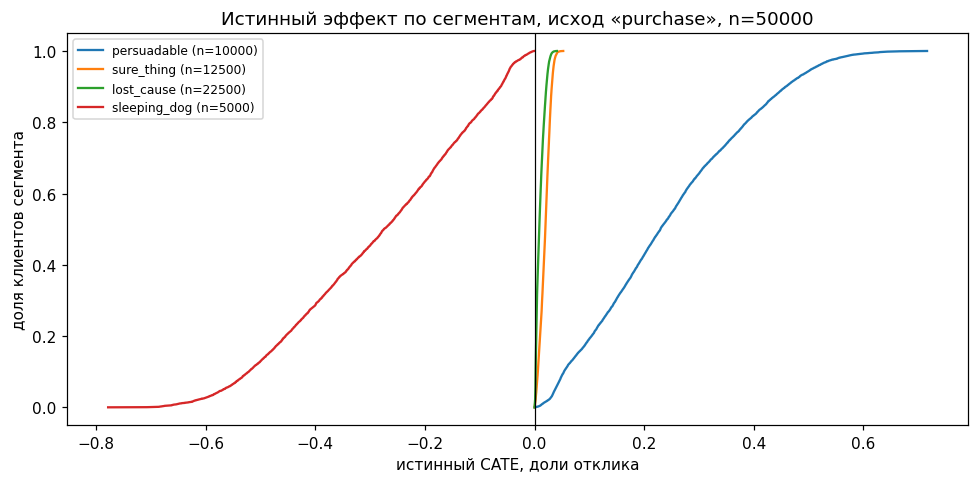

In [11]:
def plot_ite_by_segment(dataset, outcome: str) -> plt.Figure:
    """ECDF истинного CATE по сегментам. Единицы — доли отклика."""
    fig, ax = plt.subplots()
    ite = dataset.ite_true[outcome]
    for segment in ["persuadable", "sure_thing", "lost_cause", "sleeping_dog"]:
        values = np.sort(ite[dataset.segment == segment].to_numpy())
        if len(values) == 0:
            continue
        ax.plot(values, np.arange(1, len(values) + 1) / len(values),
                label=f"{segment} (n={len(values)})")
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("истинный CATE, доли отклика")
    ax.set_ylabel("доля клиентов сегмента")
    ax.set_title(f"Истинный эффект по сегментам, исход «{outcome}», n={dataset.n}")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


fig = plot_ite_by_segment(data, "purchase")
fig.savefig(out_path("figures", f"ite_by_segment_{RUN_DATE}", "png"))
plt.show()

## Обучающая выборка для ноутбука 03

Сохраняем один базовый эксперимент, чтобы ноутбук 03 не пересобирал его заново.
Имя файла несёт дату прогона: `data/interim` — это кэш, а не источник.

In [12]:
interim = PROJECT_DIR / "data" / "interim"
interim.mkdir(parents=True, exist_ok=True)
frame = exp.features.copy()
frame["treatment"] = exp.treatment
for outcome in ("purchase", "activation"):
    frame[f"y_{outcome}"] = exp.outcomes[outcome]
    frame[f"ite_true_{outcome}"] = exp.ite_true[outcome]
frame["segment"] = exp.segment
stem = f"experiment_control{int(CONTROL_SHARE * 100)}_{RUN_DATE}"
try:
    path = interim / f"{stem}.parquet"
    frame.to_parquet(path)
except ImportError:
    # pyarrow не установлен — кладём csv.gz, чтобы прогон не вставал из-за формата
    path = interim / f"{stem}.csv.gz"
    frame.to_csv(path, index=True)
    print("pyarrow недоступен, сохранено в csv.gz; для parquet: pip install pyarrow")
print("строк %d, колонок %d ->" % frame.shape, path.name)
print("\nверсии:", "pandas", pd.__version__, "| numpy", np.__version__)

строк 50000, колонок 27 -> experiment_control30_2026-10-01.parquet

версии: pandas 2.2.3 | numpy 1.24.3


## Порог окупаемости канала и доля аудитории

Вход для экономики статьи. Порог считается из цены контакта и ценности
целевого действия, доля — по распределению ИСТИННОГО эффекта, то есть это
потолок: сколько клиентов отобрал бы идеальный отбор. Доля наследует
конструкцию генератора (убеждаемых 20% по построению) и измерением не является.


In [ ]:
SMS_RUB, VALUE_RUB = 5.75, 120.0        # docs/cost_inputs.yaml: sms, benchmarks
BASE, CAMPAIGNS, OLD_AUDIENCE = 1_000_000, 12, 400_000   # допущения отчёта по практике

ite = data.ite_true["purchase"].to_numpy()
thr = SMS_RUB / VALUE_RUB
above = ite > thr
share, mean_eff = above.mean(), ite[above].mean()
print(f"порог окупаемости SMS = {SMS_RUB} / {VALUE_RUB} = {thr*100:.2f} п.п.")
print(f"доля базы выше порога = {share:.4f}, средний эффект в этой группе = {mean_eff:.4f}")

rows = []
for s in (share, 0.25, 0.30, OLD_AUDIENCE / BASE):
    sent = CAMPAIGNS * BASE * s
    rows.append({
        "доля базы в рассылке": s,
        "сообщений в год, млн": sent / 1e6,
        "затраты на SMS, млн руб": sent * SMS_RUB / 1e6,
        "экономия, млн руб": (CAMPAIGNS * OLD_AUDIENCE - sent) * SMS_RUB / 1e6,
    })
econ = pd.DataFrame(rows).round(2)
print()
print(econ.to_string(index=False))
econ.to_csv(out_path("tables", f"economics_sms_{RUN_DATE}", "csv"), index=False)

# прирост целевых действий за одну кампанию: потолок и модельный отбор
VALUE_RATIO = 0.694   # ценность@30% от оракула у S-learner, ноутбук 03
inc = BASE * share * mean_eff
print(f"\nприрост покупок за кампанию: потолок {inc/1e3:.1f} тыс. "
      f"= {inc*VALUE_RUB/1e6:.2f} млн руб невыплаченного кэшбэка")
print(f"  при отборе по S-learner: {inc*VALUE_RATIO/1e3:.1f} тыс. "
      f"= {inc*VALUE_RATIO*VALUE_RUB/1e6:.2f} млн руб")
print("ОГОВОРКА: доля аудитории задана генератором, на банке не измерена;\n"
      "перенос на год требует модели повторного отклика, которой в работе нет.")
